In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import preprocess_input

img_shape = 224
batch_size = 64
DATA_DIR = '/kaggle/input/datasets/smrnahin/hybrid/Original'
ALLOWED_CLASSES = ['Diabetic Retinopathy', 'Healthy', 'Macular Scar', 'Myopia']

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input, validation_split=0.2,
    rotation_range=15, zoom_range=0.15, width_shift_range=0.15, height_shift_range=0.15, 
    horizontal_flip=False, fill_mode='nearest'
)
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input, validation_split=0.2)
train_data = train_datagen.flow_from_directory(DATA_DIR, classes=ALLOWED_CLASSES, subset='training', target_size=(img_shape, img_shape), class_mode="categorical", batch_size=batch_size, seed=42)
validation_data = val_datagen.flow_from_directory(DATA_DIR, classes=ALLOWED_CLASSES, subset='validation', target_size=(img_shape, img_shape), class_mode="categorical", shuffle=False, batch_size=batch_size, seed=42)

2026-05-28 15:57:15.718938: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779983835.949329      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779983836.012275      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779983836.521494      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779983836.521536      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779983836.521539      58 computation_placer.cc:177] computation placer alr

Found 2784 images belonging to 4 classes.
Found 693 images belonging to 4 classes.


In [2]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout, BatchNormalization, Flatten, Dense
from tensorflow.keras.optimizers import Adam

base_model = ResNet50(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = True
for layer in base_model.layers[:-50]: layer.trainable = False

def Create_Model():
    model = Sequential([
        base_model, Dropout(0.25), BatchNormalization(), Flatten(),
        Dense(64, activation='relu'), BatchNormalization(), Dropout(0.5), Dense(4, activation='softmax')
    ])
    return model

model = Create_Model()
model.compile(optimizer=Adam(learning_rate=1e-4), loss='categorical_crossentropy', metrics=['accuracy'])

I0000 00:00:1779983852.990156      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

callbacks = [
    ModelCheckpoint("ResNet50_Best.keras", monitor="val_accuracy", save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, verbose=1)
]

history = model.fit(
    train_data, validation_data=validation_data, epochs=50, callbacks=callbacks, 
    steps_per_epoch=train_data.n // train_data.batch_size, validation_steps=validation_data.n // validation_data.batch_size
)

Epoch 1/50


I0000 00:00:1779983877.674180     139 service.cc:152] XLA service 0x7afd200039b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779983877.674239     139 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1779983881.166806     139 cuda_dnn.cc:529] Loaded cuDNN version 91002


 1/43 ━━━━━━━━━━━━━━━━━━━━ 24:24 35s/step - accuracy: 0.2188 - loss: 2.3294

I0000 00:00:1779983895.660363     139 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5449 - loss: 1.3417
Epoch 1: val_accuracy improved from None to 0.61719, saving model to ResNet50_Best.keras

Epoch 1: finished saving model to ResNet50_Best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 152s 3s/step - accuracy: 0.6665 - loss: 0.9816 - val_accuracy: 0.6172 - val_loss: 3.0846 - learning_rate: 1.0000e-04
Epoch 2/50
 1/43 ━━━━━━━━━━━━━━━━━━━━ 5s 135ms/step - accuracy: 0.8438 - loss: 0.4166

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_accuracy improved from 0.61719 to 0.62031, saving model to ResNet50_Best.keras

Epoch 2: finished saving model to ResNet50_Best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 13s 306ms/step - accuracy: 0.8438 - loss: 0.4166 - val_accuracy: 0.6203 - val_loss: 3.0165 - learning_rate: 1.0000e-04
Epoch 3/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7964 - loss: 0.5892
Epoch 3: val_accuracy improved from 0.62031 to 0.72656, saving model to ResNet50_Best.keras

Epoch 3: finished saving model to ResNet50_Best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 85s 2s/step - accuracy: 0.8040 - loss: 0.5713 - val_accuracy: 0.7266 - val_loss: 1.5334 - learning_rate: 1.0000e-04
Epoch 4/50
 1/43 ━━━━━━━━━━━━━━━━━━━━ 5s 133ms/step - accuracy: 0.8281 - loss: 0.5901
Epoch 4: val_accuracy improved from 0.72656 to 0.72812, saving model to ResNet50_Best.keras

Epoch 4: finished saving model to ResNet50_Best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 13s 304ms/step - accuracy: 0.8281 - loss: 0.5901 - val_accuracy: 0.7281 -

In [4]:
import numpy as np
from sklearn.metrics import classification_report

score = model.evaluate(validation_data, steps=len(validation_data))
validation_data.reset()
Y_pred = model.predict(validation_data, steps=len(validation_data))
predictions = np.argmax(Y_pred, axis=1)

true_labels = validation_data.classes
class_names = list(validation_data.class_indices.keys())
report = classification_report(true_labels, predictions, target_names=class_names)
print(report)
with open("ResNet50_Report.txt", "w") as f: f.write(report)

11/11 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.8773 - loss: 0.4671
11/11 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step
                      precision    recall  f1-score   support

Diabetic Retinopathy       0.96      0.93      0.94       301
             Healthy       0.86      0.97      0.91       204
        Macular Scar       0.69      0.61      0.65        88
              Myopia       0.83      0.77      0.80       100

            accuracy                           0.88       693
           macro avg       0.83      0.82      0.83       693
        weighted avg       0.88      0.88      0.88       693



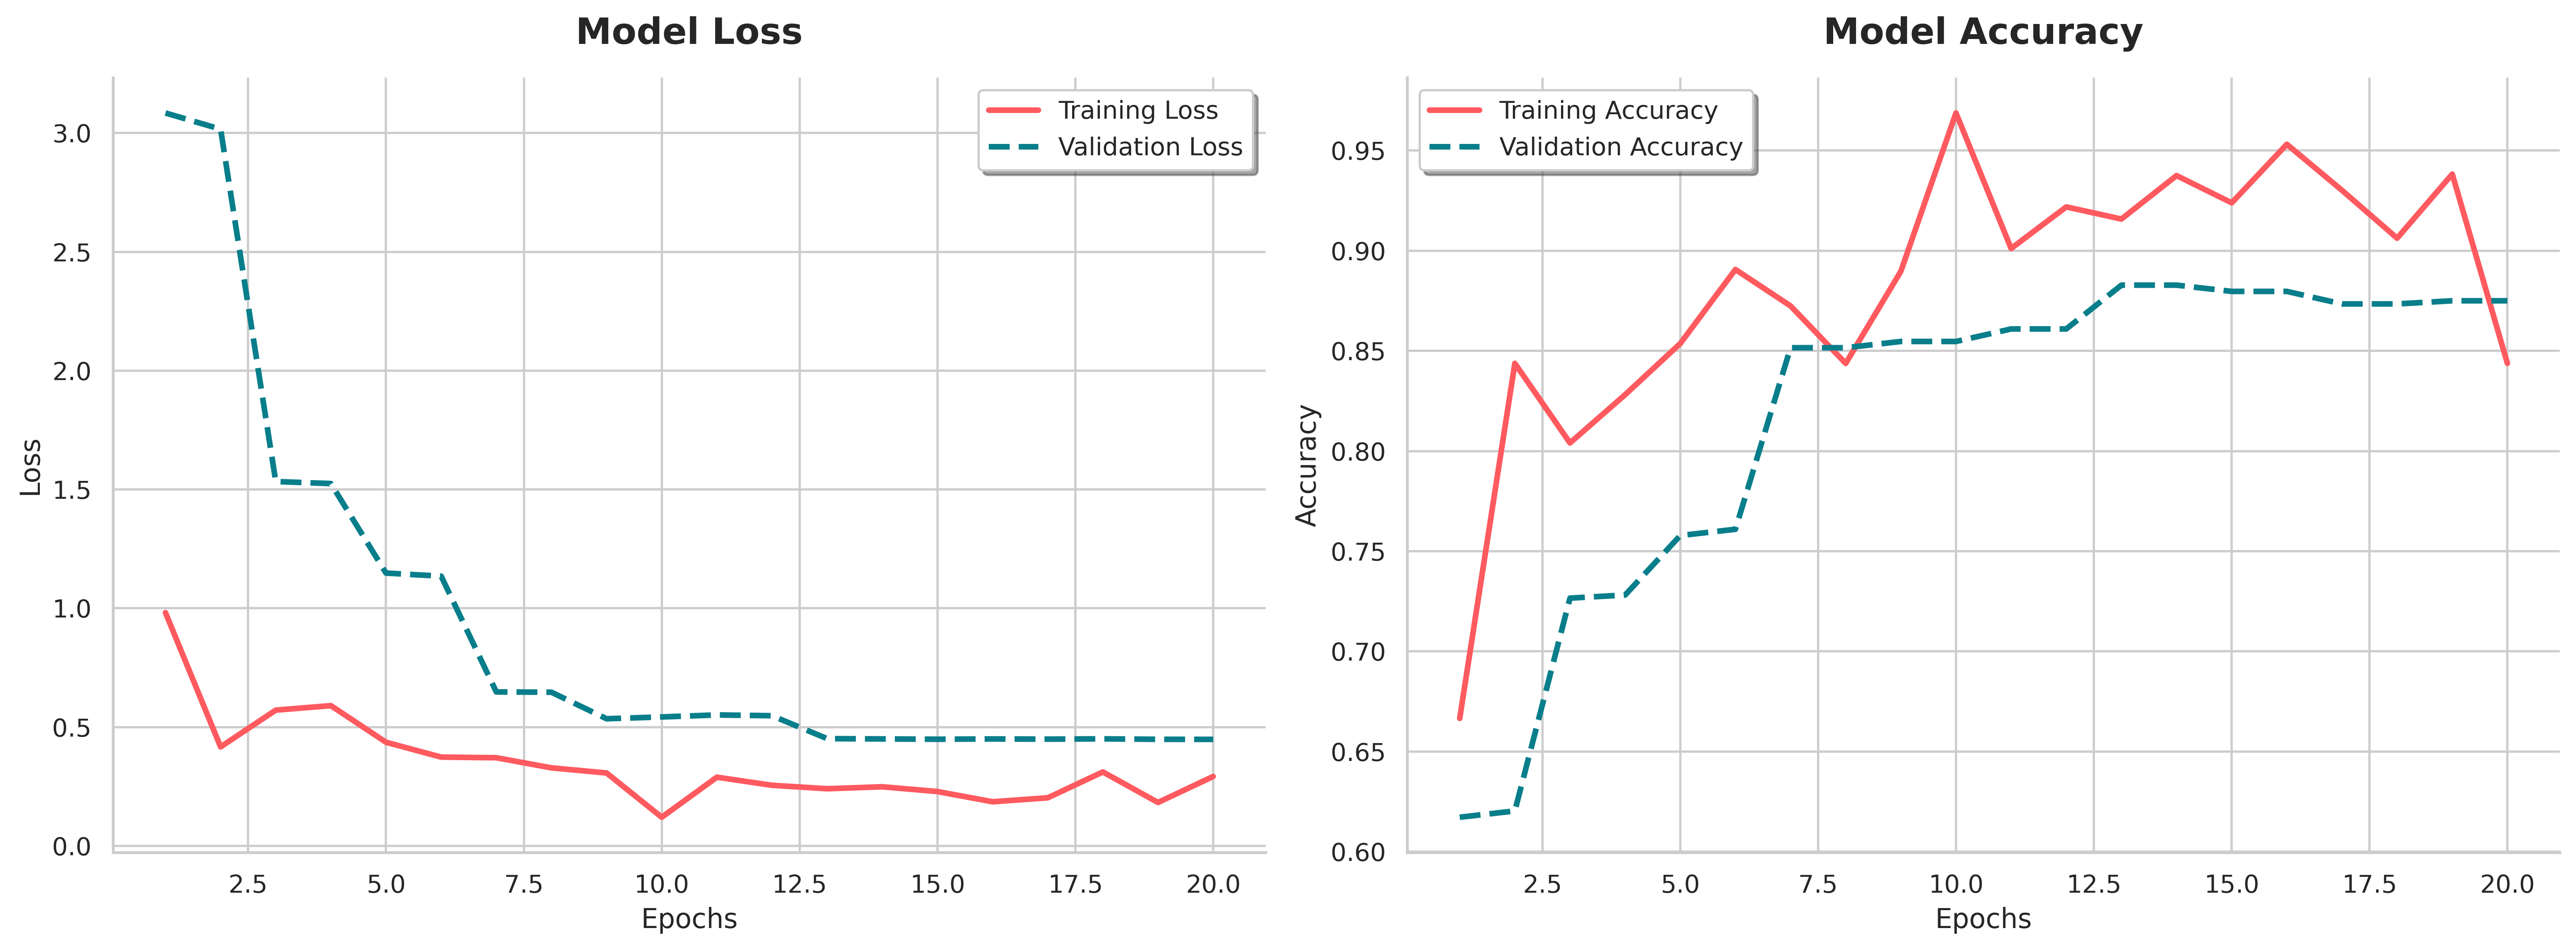

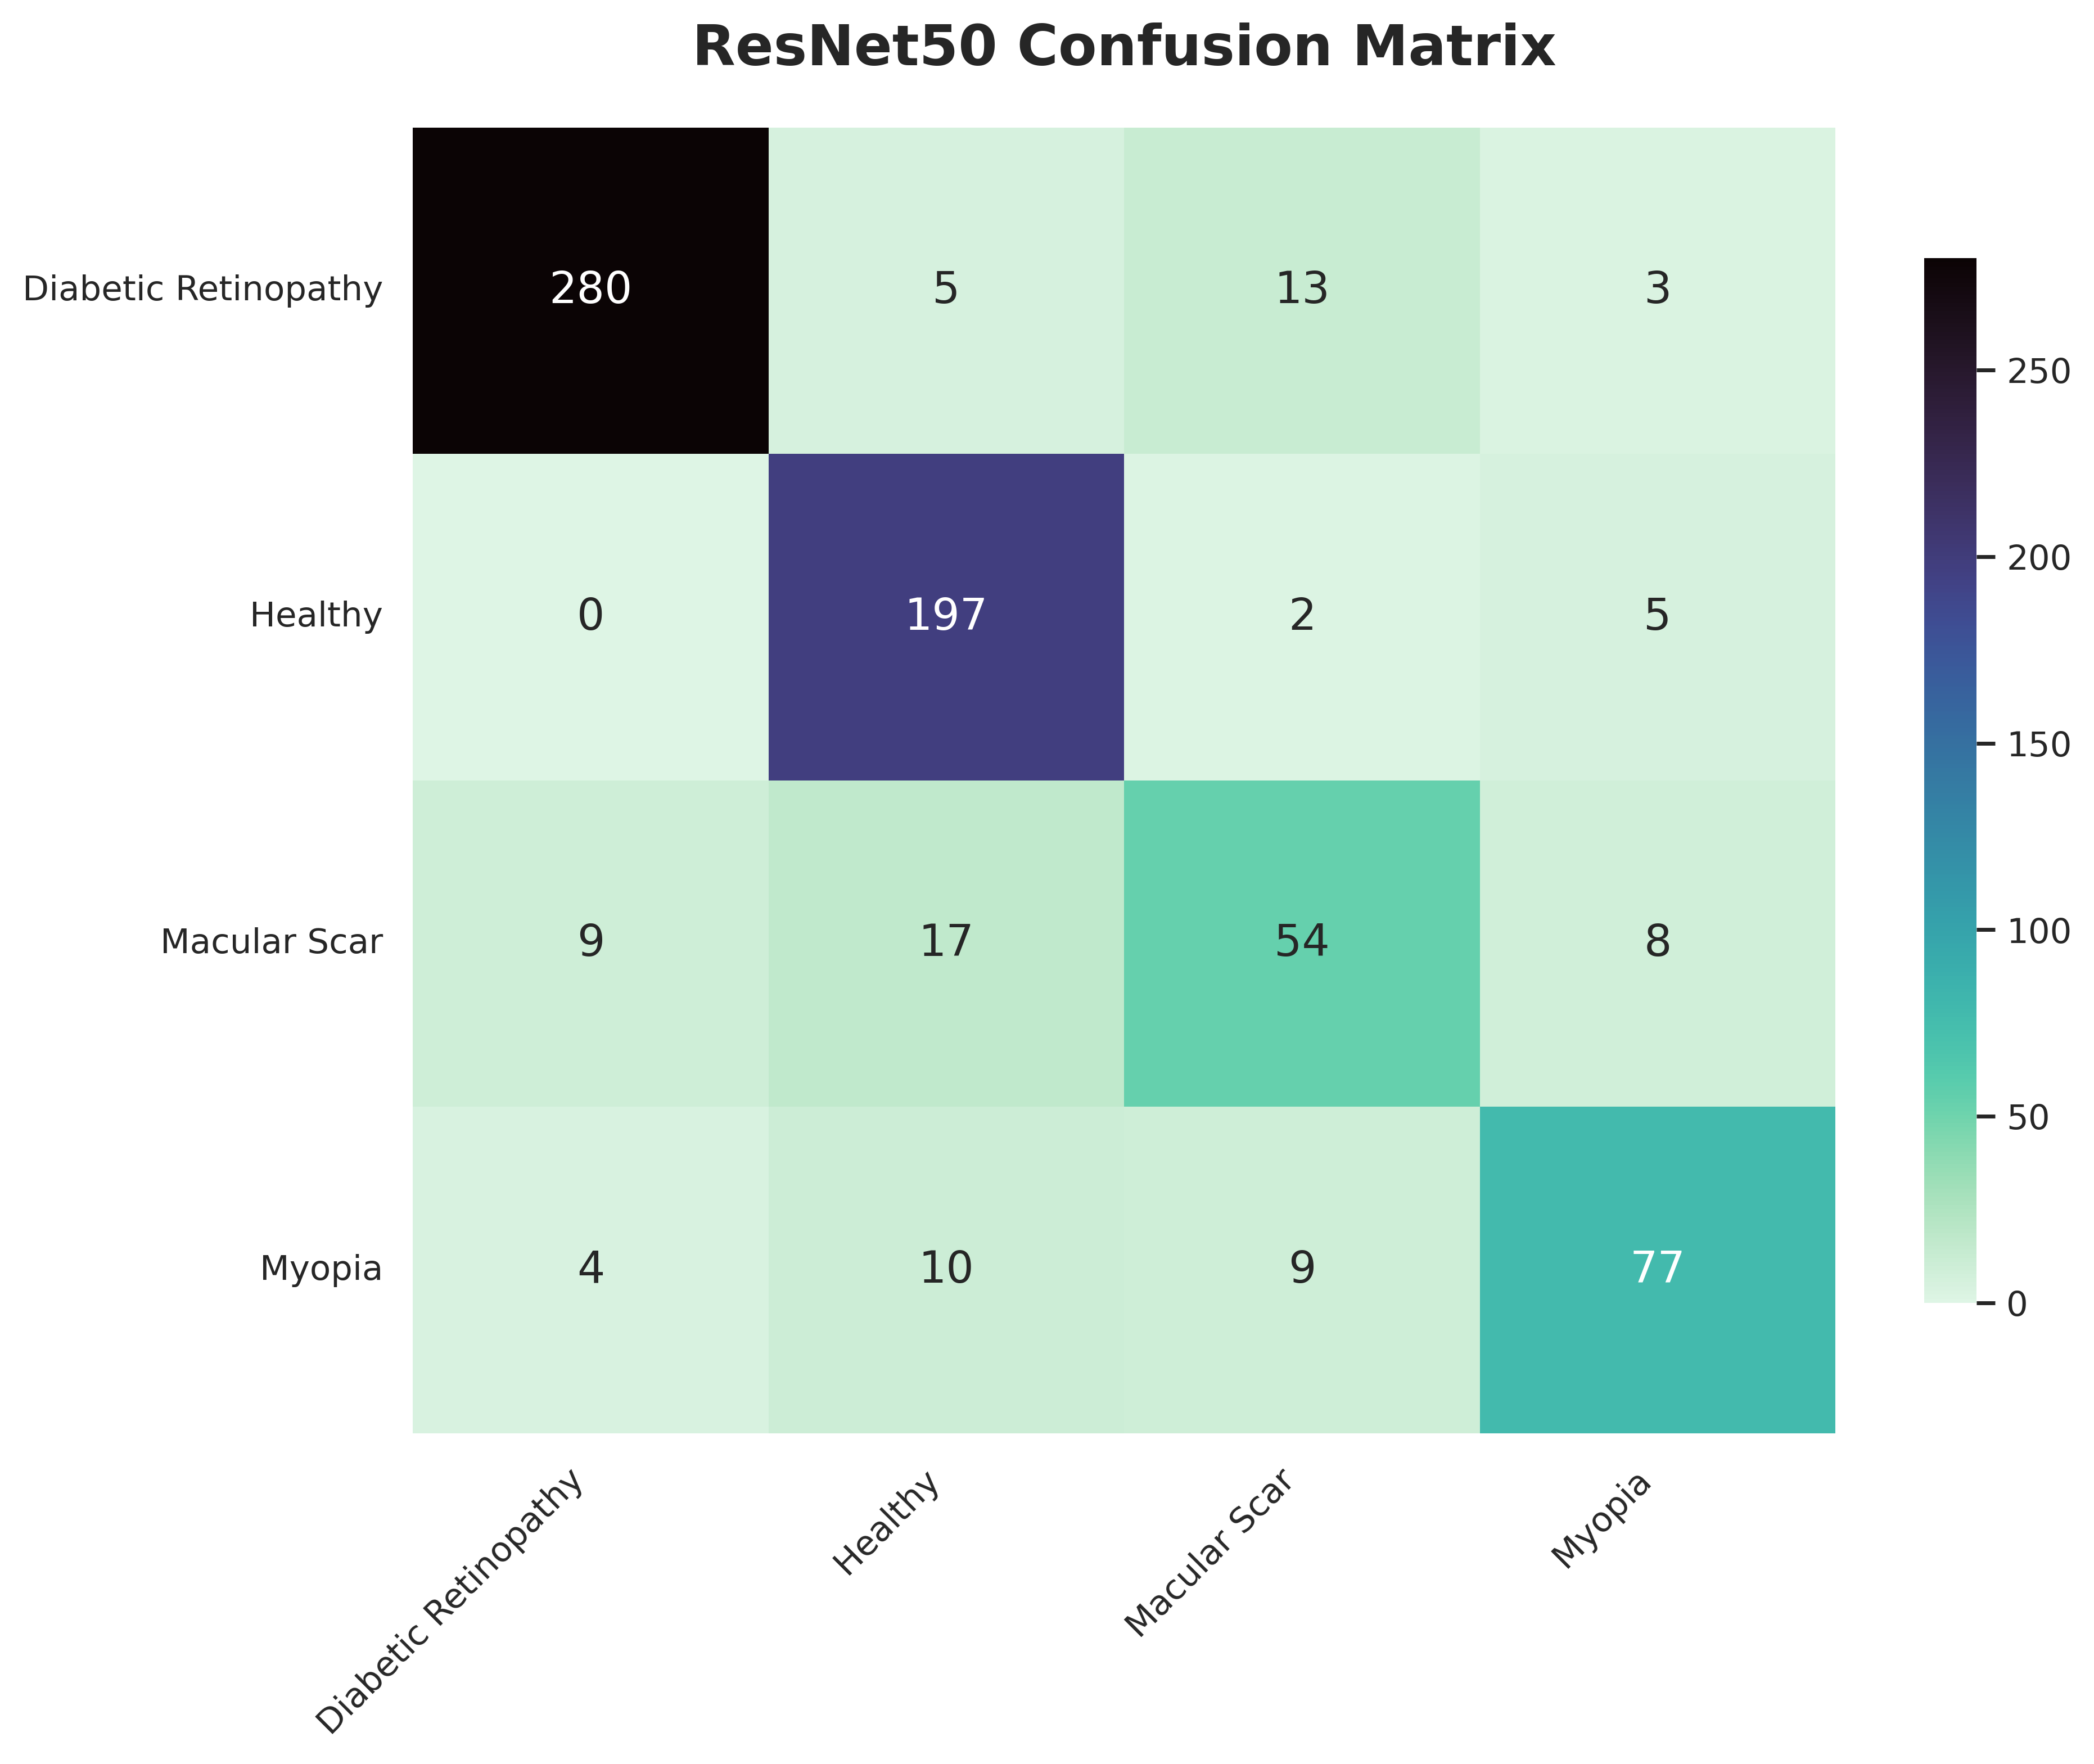

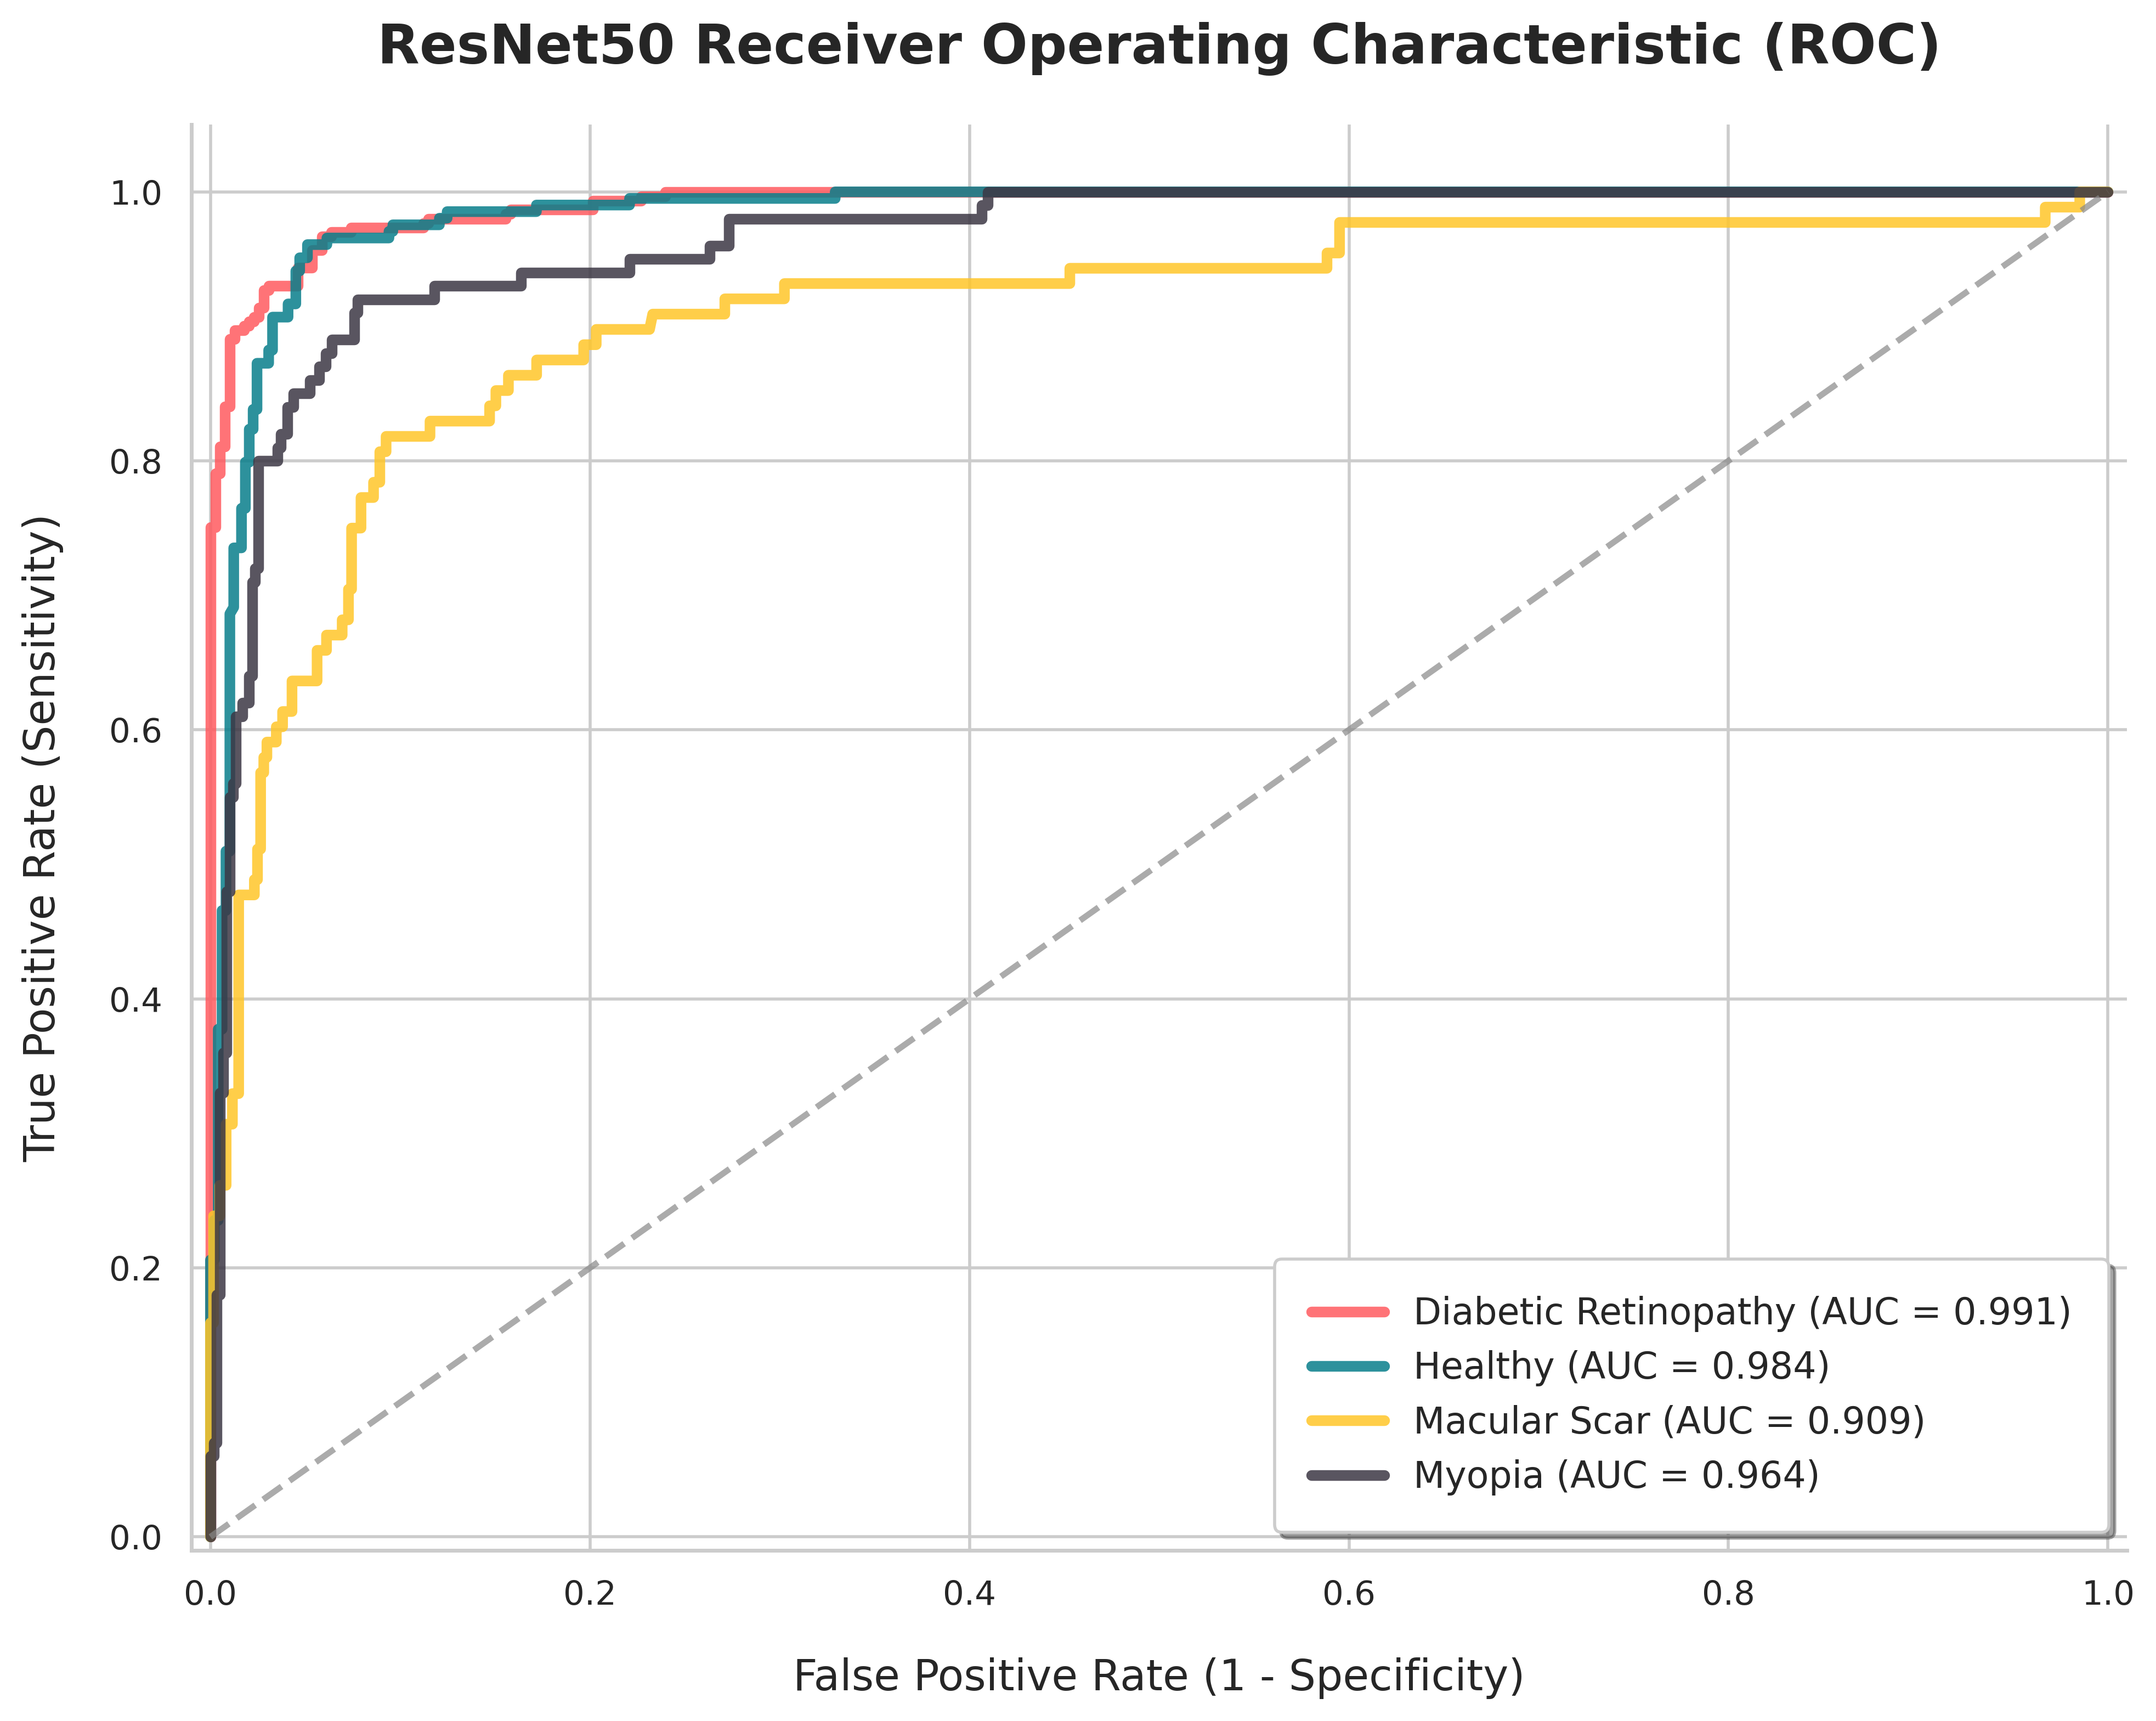

All outputs for ResNet50 successfully generated, displayed, and zipped!


/kaggle/working/ResNet50_Evaluations.zip

In [5]:
# 1. FIX: Ultra-crisp rendering for your Kaggle screen
%config InlineBackend.figure_format = 'retina'  

MODEL_NAME = "ResNet50"  

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import zipfile
import os
from IPython.display import FileLink, display

sns.set_theme(style="whitegrid", palette="muted")
model.save(f'final_{MODEL_NAME}.keras')

epochs = range(1, len(history.history["loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=200)

ax1.plot(epochs, history.history["loss"], color='#FF5A5F', lw=2.5, label="Training Loss")
ax1.plot(epochs, history.history["val_loss"], color='#087E8B', lw=2.5, linestyle='--', label="Validation Loss")
ax1.set_title("Model Loss", fontsize=16, fontweight='bold', pad=15)
ax1.set_xlabel("Epochs", fontsize=12)
ax1.set_ylabel("Loss", fontsize=12)
ax1.legend(frameon=True, shadow=True)

ax2.plot(epochs, history.history["accuracy"], color='#FF5A5F', lw=2.5, label="Training Accuracy")
ax2.plot(epochs, history.history["val_accuracy"], color='#087E8B', lw=2.5, linestyle='--', label="Validation Accuracy")
ax2.set_title("Model Accuracy", fontsize=16, fontweight='bold', pad=15)
ax2.set_xlabel("Epochs", fontsize=12)
ax2.set_ylabel("Accuracy", fontsize=12)
ax2.legend(frameon=True, shadow=True)

sns.despine(); plt.tight_layout()
plt.savefig(f'{MODEL_NAME}_curves.png', dpi=600, bbox_inches='tight'); plt.show() 

plt.figure(figsize=(10, 8), dpi=200)
cm = confusion_matrix(true_labels, predictions)
sns.heatmap(cm, annot=True, fmt='g', cmap='mako_r', annot_kws={"size": 14}, xticklabels=class_names, yticklabels=class_names, cbar_kws={'shrink': .8})
plt.title(f'{MODEL_NAME} Confusion Matrix', fontsize=18, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=11); plt.yticks(rotation=0, fontsize=11)
plt.tight_layout()
plt.savefig(f'{MODEL_NAME}_cm.png', dpi=600, bbox_inches='tight'); plt.show()

true_labels_binarized = label_binarize(true_labels, classes=[0, 1, 2, 3])
num_classes = len(class_names)
fpr, tpr, roc_auc = dict(), dict(), dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(true_labels_binarized[:, i], Y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(10, 8), dpi=200)
colors = ['#FF5A5F', '#087E8B', '#FFC629', '#3C3744']
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=3.5, alpha=0.85, label=f'{class_names[i]} (AUC = {roc_auc[i]:.3f})')
plt.plot([0, 1], [0, 1], color='#888888', lw=2, linestyle='--', alpha=0.7)
plt.xlim([-0.01, 1.01]); plt.ylim([-0.01, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=14, fontweight='500', labelpad=15)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=14, fontweight='500', labelpad=15)
plt.title(f'{MODEL_NAME} Receiver Operating Characteristic (ROC)', fontsize=18, fontweight='bold', pad=20)
plt.legend(loc="lower right", fontsize=12, frameon=True, shadow=True, borderpad=1)
sns.despine(); plt.tight_layout()
plt.savefig(f'{MODEL_NAME}_ROC_Curve.png', dpi=600, bbox_inches='tight'); plt.show() 

pd.DataFrame({"Class": class_names, "AUC_Score": [roc_auc[i] for i in range(num_classes)]}).to_csv(f'{MODEL_NAME}_AUC_Scores.csv', index=False)

zip_name = f"{MODEL_NAME}_Evaluations.zip"
files = [f"{MODEL_NAME}_Best.keras", f"final_{MODEL_NAME}.keras", f"{MODEL_NAME}_Report.txt", f"{MODEL_NAME}_curves.png", f"{MODEL_NAME}_cm.png", f"{MODEL_NAME}_ROC_Curve.png", f"{MODEL_NAME}_AUC_Scores.csv"]
with zipfile.ZipFile(zip_name, 'w') as zipf:
    for f in files:
        if os.path.exists(f): zipf.write(f)

print(f"All outputs for {MODEL_NAME} successfully generated, displayed, and zipped!")
display(FileLink(zip_name))